# Results Visualization — ACSIncome (Illinois, 2018)

Visualize held-out test performance for Logistic Regression and Random Forest across four strategies: Baseline, Reweighing, Threshold Optimization, and Exponentiated Gradient. The figures compare predictive performance, group fairness disparities, and bootstrap confidence intervals.

## Load final test results

Use one results table with eight configurations and one confidence-interval table. The test results are descriptive; uncertainty intervals are based on fixed test predictions.

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
results_dir = PROJECT_ROOT / "results"

results = pd.read_csv(results_dir / "final_test_comparison.csv")
confidence_intervals = pd.read_csv(results_dir / "bootstrap_confidence_intervals.csv")

strategies = [
    "Baseline", "Reweighing", "Threshold Optimization", "ExponentiatedGradient"
]
models = ["Logistic Regression", "Random Forest"]
model_styles = {
    "Logistic Regression": {"color": "#2764A5", "marker": "o"},
    "Random Forest": {"color": "#D97732", "marker": "s"},
}
strategy_labels = ["Baseline", "Reweighing", "Threshold optimization", "Exponentiated gradient"]

results["Configuration"] = results["Model"] + " | " + results["Strategy"]
results = results.merge(confidence_intervals, on="Configuration", validate="one_to_one")
display(results[["Model", "Strategy", "Accuracy", "EOD", "DPD", "FPR Gap"]].round(4))

,Model,Strategy,Accuracy,EOD,DPD,FPR Gap
0,Logistic Regression,Baseline,0.8081,0.0342,0.1385,0.0506
1,Logistic Regression,Reweighing,0.8058,0.0312,0.0906,0.0128
2,Logistic Regression,Threshold Optimization,0.8034,0.0117,0.1274,0.0420
3,Logistic Regression,ExponentiatedGradient,0.8066,0.0155,0.1245,0.0398
4,Random Forest,Baseline,0.7931,0.0180,0.1221,0.0434
5,Random Forest,Reweighing,0.7940,0.0118,0.1019,0.0280
6,Random Forest,Threshold Optimization,0.7856,0.0080,0.1054,0.0238
7,Random Forest,ExponentiatedGradient,0.7945,0.0279,0.1262,0.0434


## Accuracy and equal opportunity gap

Higher Accuracy is preferable; lower absolute EOD indicates smaller differences in true positive rates. Horizontal bars show 95% percentile bootstrap confidence intervals. These are not intervals for retraining variability.

In [7]:
def plot_metric(metric, xlabel, filename, lower=None, upper=None):
    fig, ax = plt.subplots(figsize=(9, 4.6))
    positions = np.arange(len(strategies))

    for model, offset in zip(models, (-0.13, 0.13)):
        subset = results[results["Model"] == model].set_index("Strategy").loc[strategies]
        values = subset[metric].to_numpy()
        errors = None
        if lower and upper:
            errors = np.vstack([
                values - subset[lower].to_numpy(),
                subset[upper].to_numpy() - values,
            ])
        ax.errorbar(
            values, positions + offset, xerr=errors,
            fmt=model_styles[model]["marker"],
            color=model_styles[model]["color"],
            markersize=7, capsize=3, linestyle="none", label=model,
        )

    ax.set_yticks(positions, strategy_labels)
    ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(loc="best", frameon=False)
    fig.tight_layout()
    fig.savefig(results_dir / filename, dpi=300, bbox_inches="tight")
    plt.show()

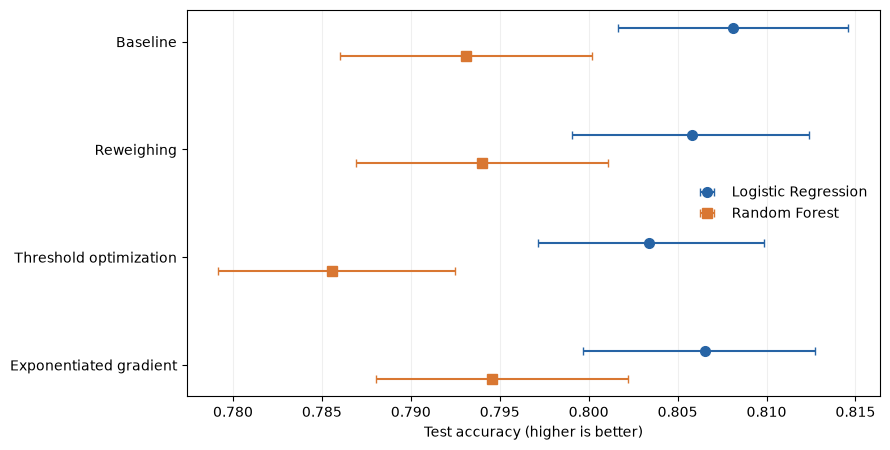

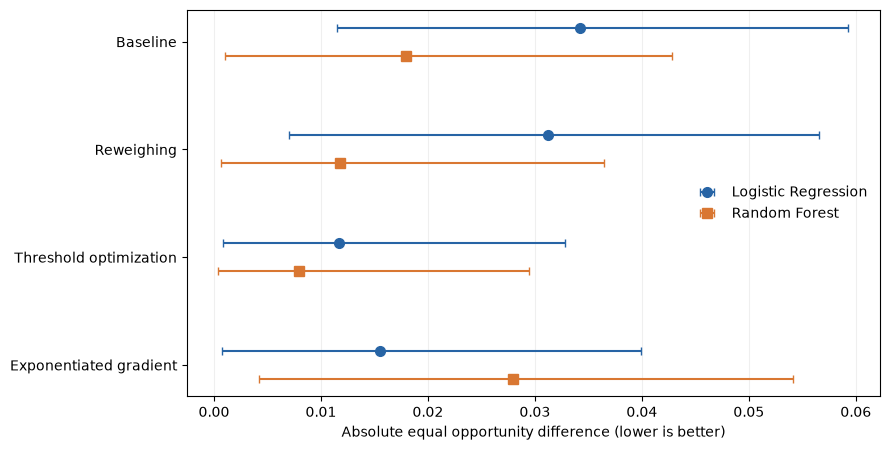

In [8]:
plot_metric(
    "Accuracy", "Test accuracy (higher is better)", "accuracy_comparison.png",
    "Accuracy CI Lower", "Accuracy CI Upper",
)
plot_metric(
    "EOD", "Absolute equal opportunity difference (lower is better)",
    "eod_comparison.png", "EOD CI Lower", "EOD CI Upper",
)

## Secondary metrics

Balanced Accuracy, demographic parity difference (DPD), and false positive rate gap provide complementary views. Improvements in EOD need not imply improvements in the other fairness gaps.

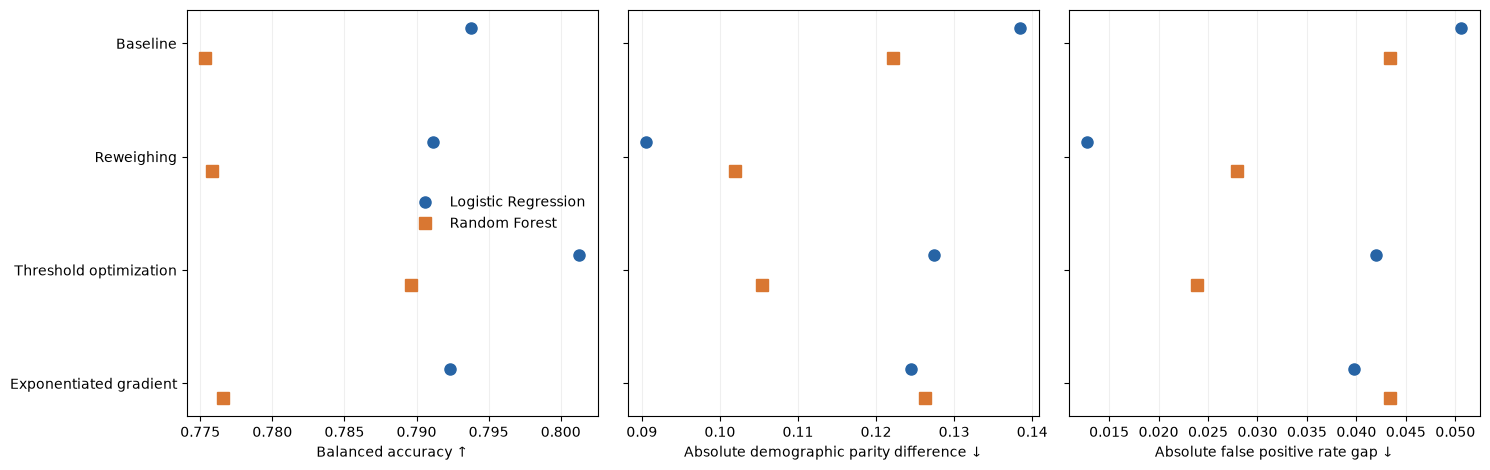

In [9]:
metrics = [
    ("Balanced Accuracy", "Balanced accuracy ↑"),
    ("DPD", "Absolute demographic parity difference ↓"),
    ("FPR Gap", "Absolute false positive rate gap ↓"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, (metric, label) in zip(axes, metrics):
    for model, offset in zip(models, (-0.13, 0.13)):
        subset = results[results["Model"] == model].set_index("Strategy").loc[strategies]
        ax.plot(
            subset[metric], np.arange(len(strategies)) + offset,
            marker=model_styles[model]["marker"],
            color=model_styles[model]["color"],
            linestyle="none", markersize=8, label=model,
        )
    ax.set_xlabel(label)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

axes[0].set_yticks(np.arange(len(strategies)), strategy_labels)
axes[0].invert_yaxis()
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(results_dir / "secondary_metrics_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## Comparison with Baseline

Report the change in Accuracy in percentage points and the relative EOD reduction for each model. Negative EOD reduction indicates an increased gap. The corresponding summary is already generated by `06_final_evaluation.ipynb`, so this notebook does not overwrite it.

In [10]:
tradeoffs = pd.read_csv(results_dir / "tradeoff_summary.csv")
display(tradeoffs.round(2))

,Model,Strategy,Accuracy Change (pp),EOD Reduction (%)
0,Logistic Regression,Baseline,0.00,0.00
1,Logistic Regression,Reweighing,-0.23,8.66
2,Logistic Regression,Threshold Optimization,-0.47,65.86
3,Logistic Regression,ExponentiatedGradient,-0.16,54.75
4,Random Forest,Baseline,0.00,0.00
5,Random Forest,Reweighing,0.09,34.24
6,Random Forest,Threshold Optimization,-0.75,55.72
7,Random Forest,ExponentiatedGradient,0.14,-55.40


## Interpretation

These plots summarize the observed fairness–accuracy trade-offs on the held-out test set. Error bars indicate sampling uncertainty conditional on fitted models and fixed predictions, not repeated training. No single fairness metric captures every dimension of group disparity, and observed gaps do not establish discriminatory causation.